In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Persiapan Data (Simulasi Data Konter HP)
Menyimulasikan data penjualan harian selama 6 bulan terakhir beserta stok awalnya.

In [2]:
np.random.seed(42)
dates = pd.date_range(start='2023-01-01', end='2023-06-30', freq='D')
products = [
    'Pulsa Telkomsel 20k', 'Voucher Kuota XL 5GB', 'Pulsa Indosat 10k', 'Perdana Axis',
    'Kabel Data Type-C', 'Tempered Glass Bening', 'Softcase Silikon', 'Earphone Standar',
    'Charger Adaptor 20W', 'MicroSD 32GB', 'Powerbank 10000mAh', 'Speaker Bluetooth Mini',
    'Tongsis Bluetooth', 'Holder HP Mobil', 'Headset Gaming'
]

# Menentukan stok awal untuk masing-masing produk (disesuaikan dengan skala penjualan)
stok_awal = {
    'Pulsa Telkomsel 20k': 2500, 'Voucher Kuota XL 5GB': 2000, 'Pulsa Indosat 10k': 2500, 'Perdana Axis': 1500,
    'Kabel Data Type-C': 500, 'Tempered Glass Bening': 800, 'Softcase Silikon': 700, 'Earphone Standar': 400,
    'Charger Adaptor 20W': 200, 'MicroSD 32GB': 200, 'Powerbank 10000mAh': 100, 'Speaker Bluetooth Mini': 50,
    'Tongsis Bluetooth': 30, 'Holder HP Mobil': 30, 'Headset Gaming': 20
}

data = []
for product in products:
    if product in ['Pulsa Telkomsel 20k', 'Voucher Kuota XL 5GB', 'Pulsa Indosat 10k', 'Perdana Axis']:
        base = 12
    elif product in ['Kabel Data Type-C', 'Tempered Glass Bening', 'Softcase Silikon', 'Earphone Standar']:
        base = 5
    elif product in ['Charger Adaptor 20W', 'MicroSD 32GB', 'Powerbank 10000mAh', 'Speaker Bluetooth Mini']:
        base = 1.5
    else:
        base = 0.1

    for date in dates:
        if base >= 1:
            sales = np.random.poisson(base)
        else:
            sales = 1 if np.random.rand() < base else 0

        # Noise
        rand_val = np.random.rand()
        if rand_val < 0.01:
            sales = np.nan
        elif rand_val < 0.02:
            sales = -5
        elif rand_val < 0.03:
            sales = sales * 50

        data.append({'Tanggal': date, 'Produk': product, 'Terjual': sales, 'Stok_Awal': stok_awal[product]})

df_raw = pd.DataFrame(data)
display(Markdown("### Data Mentah Transaksi Harian"))
display(df_raw.head())

### Data Mentah Transaksi Harian

,Tanggal,Produk,Terjual,Stok_Awal
0,2023-01-01,Pulsa Telkomsel 20k,11.0,2500
1,2023-01-02,Pulsa Telkomsel 20k,13.0,2500
2,2023-01-03,Pulsa Telkomsel 20k,650.0,2500
3,2023-01-04,Pulsa Telkomsel 20k,9.0,2500
4,2023-01-05,Pulsa Telkomsel 20k,10.0,2500


## a) Exploratory Data Analysis (EDA)
Tahap ini bertujuan untuk memahami karakteristik data secara mendalam sebelum kita membersihkannya dan memodelkannya. 
Kita akan menganalisis:
1. Pengecekan Missing Values & Outliers.
2. Analisis Statistik Produk (Jumlah Terjual, Frekuensi Transaksi, Sisa Stok).
3. Pola Penjualan dan Identifikasi Produk (Sering terjual vs Jarang bergerak).
4. Status Ketersediaan Stok (Potensi Kekurangan vs Kelebihan).

### 1. Pengecekan Missing Values dan Anomali Data

Tanggal       0
Produk        0
Terjual      29
Stok_Awal     0
dtype: int64

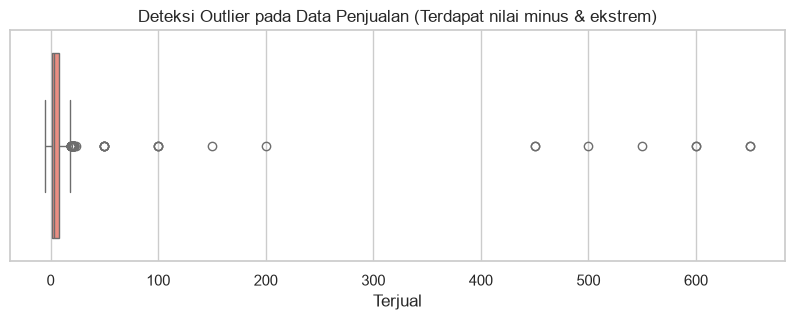

In [3]:
display(Markdown("### 1. Pengecekan Missing Values dan Anomali Data"))
display(df_raw.isnull().sum())

plt.figure(figsize=(10, 3))
sns.boxplot(x=df_raw['Terjual'], color='salmon')
plt.title('Deteksi Outlier pada Data Penjualan (Terdapat nilai minus & ekstrem)')
plt.show()

**Sebelum melanjutkan EDA secara mendalam, kita akan melakukan *Data Cleaning* terlebih dahulu agar analisis statistik (Total Terjual, dll) tidak terdistorsi oleh data yang salah (outliers & nilai negatif).**

In [4]:
# 1. Menghapus Missing Values (NaN)
df_clean = df_raw.dropna().copy()

# 2. Mengatasi data inkonsisten (penjualan tidak mungkin negatif)
df_clean = df_clean[df_clean['Terjual'] >= 0]

# 3. Menghilangkan Outliers (Menggunakan batas persentil ke-99)
Q3 = df_clean['Terjual'].quantile(0.99)
df_clean = df_clean[df_clean['Terjual'] <= Q3]

display(Markdown("Data telah dibersihkan. Total baris sekarang: " + str(len(df_clean))))

Data telah dibersihkan. Total baris sekarang: 2637

In [5]:
display(Markdown("### 2. Analisis Statistik Produk (Total Terjual, Frekuensi & Sisa Stok)"))
df_stats = df_clean.groupby('Produk').agg(
    Total_Terjual=('Terjual', 'sum'),
    Frekuensi_Transaksi=('Terjual', lambda x: (x > 0).sum()),
    Stok_Awal=('Stok_Awal', 'max') # Ambil stok awalnya
).reset_index()

df_stats['Sisa_Stok'] = df_stats['Stok_Awal'] - df_stats['Total_Terjual']

# Identifikasi Potensi Stok
def status_stok(row):
    persentase_sisa = row['Sisa_Stok'] / row['Stok_Awal']
    if persentase_sisa < 0.20:
        return 'Potensi Kekurangan Stok (Kritis)'
    elif persentase_sisa > 0.80:
        return 'Potensi Kelebihan Stok (Overstock)'
    else:
        return 'Stok Aman'

df_stats['Status_Stok'] = df_stats.apply(status_stok, axis=1)

display(df_stats.sort_values('Total_Terjual', ascending=False).reset_index(drop=True))

### 2. Analisis Statistik Produk (Total Terjual, Frekuensi & Sisa Stok)

,Produk,Total_Terjual,Frekuensi_Transaksi,Stok_Awal,Sisa_Stok,Status_Stok
0,Voucher Kuota XL 5GB,2133.0,173,2000,-133.0,Potensi Kekurangan Stok (Kritis)
1,Perdana Axis,2118.0,177,1500,-618.0,Potensi Kekurangan Stok (Kritis)
2,Pulsa Indosat 10k,2080.0,173,2500,420.0,Potensi Kekurangan Stok (Kritis)
3,Pulsa Telkomsel 20k,2043.0,172,2500,457.0,Potensi Kekurangan Stok (Kritis)
4,Earphone Standar,899.0,178,400,-499.0,Potensi Kekurangan Stok (Kritis)
5,Softcase Silikon,881.0,178,700,-181.0,Potensi Kekurangan Stok (Kritis)
6,Tempered Glass Bening,864.0,177,800,-64.0,Potensi Kekurangan Stok (Kritis)
7,Kabel Data Type-C,856.0,172,500,-356.0,Potensi Kekurangan Stok (Kritis)
8,Powerbank 10000mAh,287.0,144,100,-187.0,Potensi Kekurangan Stok (Kritis)
9,MicroSD 32GB,253.0,138,200,-53.0,Potensi Kekurangan Stok (Kritis)


### 3. Visualisasi Produk Paling Laku & Paling Jarang Bergerak

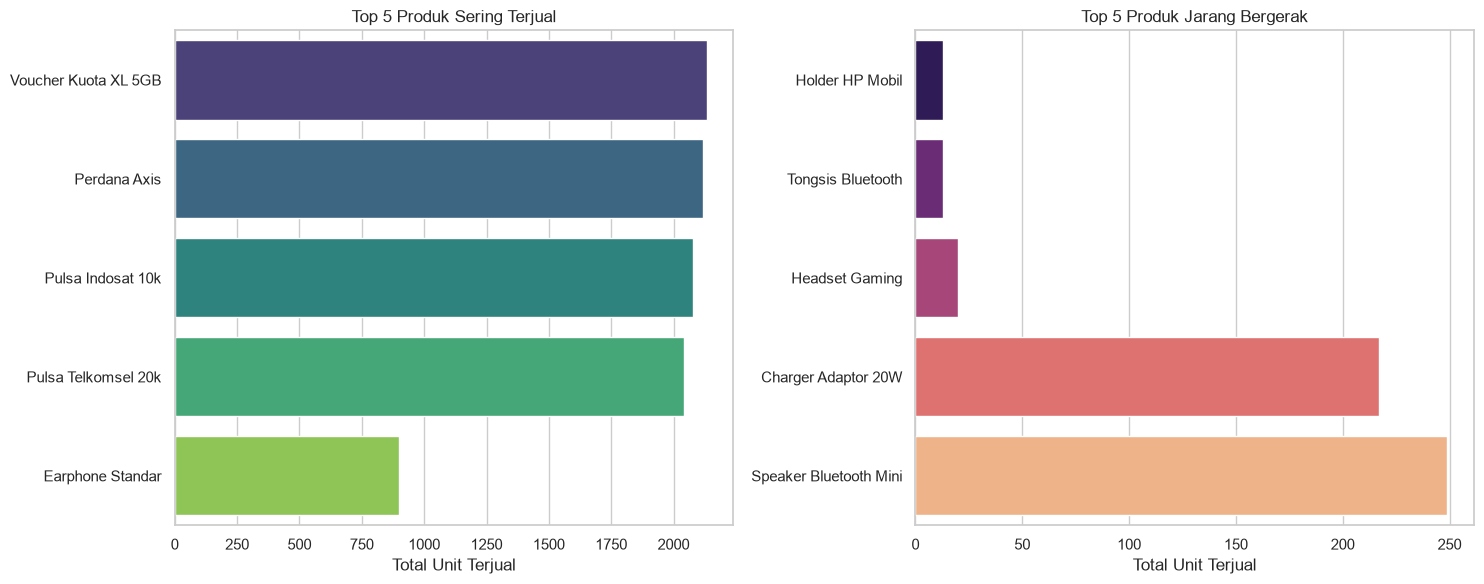

In [6]:
display(Markdown("### 3. Visualisasi Produk Paling Laku & Paling Jarang Bergerak"))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top 5
top_5 = df_stats.nlargest(5, 'Total_Terjual')
sns.barplot(data=top_5, x='Total_Terjual', y='Produk', ax=axes[0], palette='viridis')
axes[0].set_title('Top 5 Produk Sering Terjual')
axes[0].set_xlabel('Total Unit Terjual')
axes[0].set_ylabel('')

# Bottom 5
bottom_5 = df_stats.nsmallest(5, 'Total_Terjual')
sns.barplot(data=bottom_5, x='Total_Terjual', y='Produk', ax=axes[1], palette='magma')
axes[1].set_title('Top 5 Produk Jarang Bergerak')
axes[1].set_xlabel('Total Unit Terjual')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

### 4. Pola Penjualan Produk Seiring Waktu (Tren Harian)

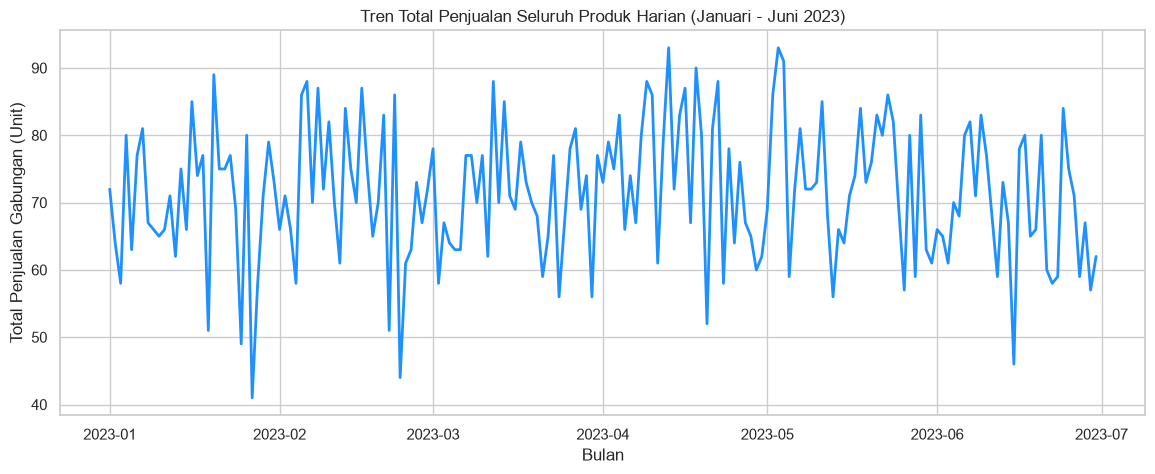

In [7]:
display(Markdown("### 4. Pola Penjualan Produk Seiring Waktu (Tren Harian)"))
df_trend = df_clean.groupby('Tanggal')['Terjual'].sum().reset_index()

plt.figure(figsize=(14, 5))
sns.lineplot(data=df_trend, x='Tanggal', y='Terjual', color='dodgerblue', linewidth=2)
plt.title('Tren Total Penjualan Seluruh Produk Harian (Januari - Juni 2023)')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan Gabungan (Unit)')
plt.show()

## c) Feature Engineering
Untuk melatih model K-Means Clustering, kita akan menggunakan fitur `Total_Terjual` dan `Frekuensi_Transaksi`. Kita menggunakan `StandardScaler` untuk melakukan *scaling* agar kedua fitur memiliki bobot skala yang seimbang di mata algoritma.

In [8]:
scaler = StandardScaler()
df_stats['Scaled_Total'] = scaler.fit_transform(df_stats[['Total_Terjual']])
df_stats['Scaled_Freq'] = scaler.fit_transform(df_stats[['Frekuensi_Transaksi']])

display(df_stats[['Produk', 'Total_Terjual', 'Frekuensi_Transaksi', 'Scaled_Total', 'Scaled_Freq']].head())

,Produk,Total_Terjual,Frekuensi_Transaksi,Scaled_Total,Scaled_Freq
0,Charger Adaptor 20W,217.0,131,-0.801054,-0.031674
1,Earphone Standar,899.0,178,0.046302,0.738322
2,Headset Gaming,20.0,20,-1.045819,-1.850174
3,Holder HP Mobil,13.0,13,-1.054516,-1.964854
4,Kabel Data Type-C,856.0,172,-0.007123,0.640025


## d) K-Means Clustering
Klasifikasi produk ke dalam 4 pergerakan: Fast, Medium, Slow, dan Dead Moving.

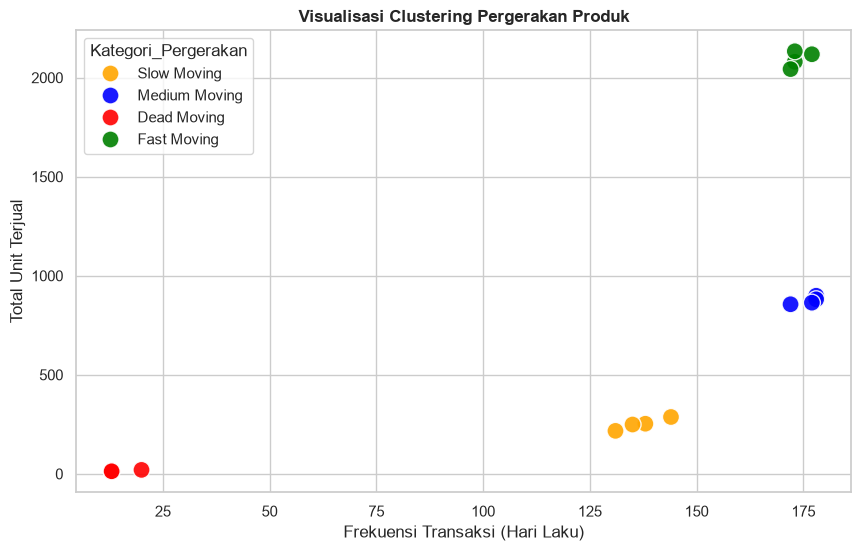

In [9]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_stats['Cluster'] = kmeans.fit_predict(df_stats[['Scaled_Total', 'Scaled_Freq']])

cluster_means = df_stats.groupby('Cluster')['Total_Terjual'].mean()
sorted_clusters = cluster_means.sort_values().index

cluster_map = {
    sorted_clusters[0]: 'Dead Moving',
    sorted_clusters[1]: 'Slow Moving',
    sorted_clusters[2]: 'Medium Moving',
    sorted_clusters[3]: 'Fast Moving'
}
df_stats['Kategori_Pergerakan'] = df_stats['Cluster'].map(cluster_map)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_stats, x='Frekuensi_Transaksi', y='Total_Terjual', 
    hue='Kategori_Pergerakan', s=150, alpha=0.9,
    palette={'Fast Moving': 'green', 'Medium Moving': 'blue', 'Slow Moving': 'orange', 'Dead Moving': 'red'}
)
plt.title('Visualisasi Clustering Pergerakan Produk', fontweight='bold')
plt.xlabel('Frekuensi Transaksi (Hari Laku)')
plt.ylabel('Total Unit Terjual')
plt.show()

## e) Rekomendasi Restock dengan Simple Moving Average (SMA)

In [10]:
window_size = 7
MINIMAL_RESTOCK = 2 

def calculate_recommendation(df_prod):
    df_prod = df_prod.sort_values('Tanggal')
    df_prod['SMA_7'] = df_prod['Terjual'].rolling(window=window_size).mean()
    last_sma = df_prod['SMA_7'].iloc[-1]

    if pd.isna(last_sma):
        rekomendasi = MINIMAL_RESTOCK
    else:
        rekomendasi = int(last_sma * 7 * 1.2) # +20% safety stock
    return max(MINIMAL_RESTOCK, rekomendasi)

rekomendasi_list = []
for product in products:
    df_prod = df_clean[df_clean['Produk'] == product].copy()
    rek = calculate_recommendation(df_prod)
    rekomendasi_list.append({'Produk': product, 'Rekomendasi_Restock': rek})

df_rekomendasi = pd.DataFrame(rekomendasi_list)
df_final = pd.merge(df_stats[['Produk', 'Kategori_Pergerakan', 'Stok_Awal', 'Total_Terjual', 'Sisa_Stok', 'Status_Stok']], df_rekomendasi, on='Produk')
df_final = df_final.sort_values('Rekomendasi_Restock', ascending=False)

display(Markdown("### Tabel Final Analisis Stok & Rekomendasi Restock"))
display(df_final.reset_index(drop=True))

### Tabel Final Analisis Stok & Rekomendasi Restock

,Produk,Kategori_Pergerakan,Stok_Awal,Total_Terjual,Sisa_Stok,Status_Stok,Rekomendasi_Restock
0,Perdana Axis,Fast Moving,1500,2118.0,-618.0,Potensi Kekurangan Stok (Kritis),109
1,Pulsa Indosat 10k,Fast Moving,2500,2080.0,420.0,Potensi Kekurangan Stok (Kritis),92
2,Pulsa Telkomsel 20k,Fast Moving,2500,2043.0,457.0,Potensi Kekurangan Stok (Kritis),91
3,Voucher Kuota XL 5GB,Fast Moving,2000,2133.0,-133.0,Potensi Kekurangan Stok (Kritis),85
4,Kabel Data Type-C,Medium Moving,500,856.0,-356.0,Potensi Kekurangan Stok (Kritis),50
5,Earphone Standar,Medium Moving,400,899.0,-499.0,Potensi Kekurangan Stok (Kritis),48
6,Softcase Silikon,Medium Moving,700,881.0,-181.0,Potensi Kekurangan Stok (Kritis),32
7,Tempered Glass Bening,Medium Moving,800,864.0,-64.0,Potensi Kekurangan Stok (Kritis),26
8,Powerbank 10000mAh,Slow Moving,100,287.0,-187.0,Potensi Kekurangan Stok (Kritis),19
9,Speaker Bluetooth Mini,Slow Moving,50,249.0,-199.0,Potensi Kekurangan Stok (Kritis),10
